# Notebook 32 — Forward compute versus input size

**Author:** Sunita Sahu · **Revision item:** A9 (token convention), follow-up F2 · CPU only

Notebook 27 priced every model on two common images (448 × 448 and 1024 × 1024). The GPU run (notebooks 29–31) then measured prefill latency on the same two images: within one model latency changed by up to 5.8×, and 20 of 171 model pairs swapped order. Two points cannot show **where** a model's cost changes, **how far** it can grow, or whether the order of two models changes again at other sizes. This notebook prices every model, with the validated tensor-level cost model of Table 3, on:

1. **square images** from 224 px to 4,096 px (4,096² is the largest image any released processor keeps at full resolution: Qwen3-VL's pixel limit; Qwen2-VL and Qwen2.5-VL stop at 3,584²);
2. **images of one pixel count (1024²) but different shapes** (aspect ratios 1:4 to 4:1).

Two predictions per input: **intrinsic** (the revised protocol of Table 3: no padding, DeepSeek-VL2's latent attention in decompressed form) and **executed** (what the reference implementation runs, as validated on the GPU: Llama-3.2-Vision's four tile slots, Idefics2's padded sub-images, DeepSeek-VL2's absorbed latent attention). Prompt length 32 tokens, as in the published protocol.

**Outputs** (`outputs/measurements/nb32_*`): the sweep tables, growth summary, order changes, vision-share ranges, executed/intrinsic ratios, aspect-ratio summary, agreement with the measured latency, a plain-text summary; and a **draft** figure (`outputs/figures/nb32_compute_vs_input_size_draft.*`; manuscript figures are rebuilt at the end of the revision).

**Re-run order.** The compute sweep does not depend on the GPU results. Section 8 reads notebook 31's outputs: re-run notebook 31 first whenever new latency results arrive (e.g. the InstructBLIP re-run), then this notebook.

---
## Setup

In [1]:
import os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd

os.environ.setdefault('HF_HUB_DISABLE_PROGRESS_BARS', '1')
NOTEBOOK_DIR = Path.cwd()
CODE_ACTIVE = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
sys.path.insert(0, str(CODE_ACTIVE))
MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
FIGURE_DIR = CODE_ACTIVE / 'outputs' / 'figures'
LOG_DIR = CODE_ACTIVE / 'outputs' / 'logs'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

from transformers.utils import logging as transformers_logging
transformers_logging.set_verbosity_error()
from vlm_audit.logging_utils import ExperimentLogger, SessionTranscript
from vlm_audit.parameter_layouts import ROSTER_TABLE_NAMES, load_parameter_shapes
from vlm_audit.input_size_sweep import (ASPECT_PIXEL_COUNT, EXECUTION_DIFFERS, INPUT_HANDLING, REFERENCE_SIDE,
                                       SMALL_SIDE, aspect_ratio_shapes, aspect_ratio_summary,
                                       executed_versus_intrinsic_by_side, findings_markdown, growth_summary,
                                       latency_agreement, order_changes_across_sweep, order_changes_between,
                                       token_budget_sweep,
                                       rank_agreement_by_side, square_shapes, sweep_inputs, vision_share_by_side,
                                       vision_share_ranges)
from vlm_audit.latency_analysis import format_p_value
pd.set_option('display.width', 230); pd.set_option('display.max_columns', 30); pd.set_option('display.max_rows', 120)

if globals().get('transcript') is not None:
    transcript.close()
transcript = SessionTranscript(LOG_DIR, '32_compute_versus_input_size')
logger = ExperimentLogger(LOG_DIR, '32_compute_versus_input_size')

TABLE_ORDER = list(ROSTER_TABLE_NAMES)
started = time.time()
parameter_shapes = {name: load_parameter_shapes(name) for name in TABLE_ORDER}
logger.info(f'parameter layouts of {len(parameter_shapes)} models loaded in {time.time() - started:.0f} s')
print(f'{len(parameter_shapes)} models')

<home>\AppData\Local\Temp\claude\<session>\0edba254-4773-49bc-b009-31568158ee2c\scratchpad\venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Session transcript: <repository>\code_active\outputs\logs\20261004_131133_32_compute_versus_input_size__session_transcript.txt
Crash traces:       <repository>\code_active\outputs\logs\20261004_131133_32_compute_versus_input_size__crash_traces.txt


23 models


---
## 1. Square sweep

Every model on every square side; one row per (model, side) with the visual tokens and the Table 3 columns (encoder, fusion, LLM-visual, LLM-text, head, total; GFLOPs) plus the executed total.

In [2]:
started = time.time()
square = sweep_inputs(parameter_shapes, square_shapes(), progress=logger.info)
square.to_csv(MEASUREMENT_DIR / 'nb32_compute_by_side.csv', index=False)
logger.info(f'square sweep: {len(square)} rows in {time.time() - started:.0f} s')
assert square['unrouted_parameters'].sum() == 0, 'a parameter matched no routing rule'
print(f'{len(square)} rows ({square.model.nunique()} models x {square.height.nunique()} sides) '
      f'in {time.time() - started:.0f} s')
(square.pivot(index='model', columns='height', values='total_g').loc[TABLE_ORDER] / 1000).round(2)

368 rows (23 models x 16 sides) in 101 s


height,224,336,448,560,672,784,896,1024,1120,1344,1568,1792,2048,2688,3584,4096
model,,,,,,,,,,,,,,,,
CLIP-ViT-L/14,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17,0.17
SigLIP-L/16,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42
SigLIP2-So400m/14,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72,0.72
ViLT-B/32,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.03
BLIP-large,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41,0.41
BLIP-2-OPT-2.7B,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86
InstructBLIP-Vicuna-7B,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37,1.37
LLaVA-1.5-7B,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47,8.47
LLaVA-NeXT-7B,18.85,18.85,47.94,47.94,47.94,47.94,47.94,47.94,47.94,47.94,47.94,47.94,47.94,47.94,47.94,47.94


Total forward compute in **TFLOPs** above. Consistency with notebook 27 at its two inputs (the tables of notebook 27 predate two later corrections of the cost model: Molmo's positional table no longer charged as a matmul, decision log N18; BLIP-2's tied LM head at its released 50,304 rows):

In [3]:
consistency_rows = []
for side in (SMALL_SIDE, REFERENCE_SIDE):
    notebook27 = pd.read_csv(MEASUREMENT_DIR / f'nb27_table3_v2_{side}.csv', index_col=0)['total_g']
    swept = square[square['height'] == side].set_index('model')['total_g']
    for model_name in TABLE_ORDER:
        relative = (swept[model_name] - notebook27[model_name]) / notebook27[model_name]
        if abs(relative) > 1e-9:
            consistency_rows.append({'side': side, 'model': model_name, 'notebook27_g': notebook27[model_name],
                                     'this_notebook_g': swept[model_name], 'relative_difference_pct': 100 * relative})
consistency = pd.DataFrame(consistency_rows)
unexplained = sorted(set(consistency['model']) - {'Molmo-7B-D', 'BLIP-2-OPT-2.7B'}) if len(consistency) else []
assert not unexplained, f'differences to notebook 27 not explained by the two corrections: {unexplained}'
print('every other model is identical to notebook 27')
consistency.round(4)

every other model is identical to notebook 27


""


---
## 2. How compute grows with the image

Per model: compute at 224, 448 and 1024 px; the plateau and the side where it is reached; the growth from 448² to the plateau; the number of distinct compute levels (a tiling moves in steps, native resolution almost continuously); and the exponent of compute in pixel count between 448² and 1024² (1 = proportional to pixels; below 1 when fixed text work dilutes it; above 1 when quadratic attention dominates).

In [4]:
growth = growth_summary(square)
growth.to_csv(MEASUREMENT_DIR / 'nb32_growth_summary.csv', index=False)
growth.round(2)

,model,input_handling,total_g_224,total_g_448,total_g_1024,total_g_plateau,saturation_side,ratio_1024_over_448,ratio_plateau_over_448,ratio_plateau_over_smallest,compute_levels,pixel_exponent_448_to_1024,executed_plateau_g,encoder_tokens_plateau
0,BLIP-2-OPT-2.7B,fixed resize,857.32,857.32,857.32,857.32,<NA>,1.00,1.00,1.00,1,0.00,857.32,257
1,BLIP-large,fixed resize,411.02,411.02,411.02,411.02,<NA>,1.00,1.00,1.00,1,0.00,411.02,577
2,CLIP-ViT-L/14,fixed resize,167.50,167.50,167.50,167.50,<NA>,1.00,1.00,1.00,1,0.00,167.50,257
3,Chameleon-7B,fixed resize,14845.99,14845.99,14845.99,14845.99,<NA>,1.00,1.00,1.00,1,0.00,14845.99,0
4,Gemma-4-12B,resize to a token budget,6422.28,6422.28,6422.28,6422.28,<NA>,1.00,1.00,1.00,1,0.00,6424.27,0
5,Gemma-4-26B-A4B,resize to a token budget,5015.49,5015.49,5015.49,5015.49,<NA>,1.00,1.00,1.00,1,0.00,5382.55,2304
6,IDEFICS-9B,fixed resize,876.28,876.28,876.28,876.28,<NA>,1.00,1.00,1.00,1,0.00,876.28,257
7,InstructBLIP-Vicuna-7B,fixed resize,1370.56,1370.56,1370.56,1370.56,<NA>,1.00,1.00,1.00,1,0.00,1370.56,257
8,LLaVA-NeXT-7B,tiling,18845.61,47941.84,47941.84,47941.84,448,1.00,1.00,2.54,2,0.00,47941.84,2885
9,Janus-Pro-7B,fixed resize,7996.24,7996.24,7996.24,7996.24,<NA>,1.00,1.00,1.00,1,0.00,7996.24,576


**Reading.** 13 of 23 models cost the same at every square side: 11 resize every image to one size, and the two Gemma 4 models resize it to a fixed token budget (their cost depends on that processor setting instead, section 6b). The other 10 grow until a plateau set by their preprocessing. Tilings reach it early: LLaVA-NeXT already at 448 px, Llama-3.2-Vision and Molmo at 672 px, DeepSeek-VL2 at 784 px, InternVL3 at 1,024 px, Idefics2 at 2,048 px (its crops reach the 980-px cap). Pixtral stops at its 1,024-px longest-edge cap. The Qwen-VL family keeps growing to its pixel limit: 3,584 px for Qwen2-VL and Qwen2.5-VL, 4,096 px for Qwen3-VL. The plateau is 244× (Qwen3-VL), 209× (Qwen2-VL) and 96× (Qwen2.5-VL, whose windowed attention keeps the encoder closer to linear) their 448² cost. Between the two GPU-measured inputs the change runs from 1.0× to 9.6× (InternVL3: one tile becomes nine tiles plus a thumbnail).

---
## 3. Which model is cheaper depends on the input

Pairs of models whose cheaper member changes (both relative gaps above 5%, the threshold of the latency analysis, so that near-ties do not count): between 448² and 1024², and anywhere in the sweep with the sides at which the order changes. Then the Kendall τ between the compute rankings at every pair of sides.

In [5]:
between = order_changes_between(square)
between.to_csv(MEASUREMENT_DIR / 'nb32_order_changes_448_1024.csv', index=False)
between_executed = order_changes_between(square, column='executed_total_g')
MODEL_PAIRS = len(TABLE_ORDER) * (len(TABLE_ORDER) - 1) // 2
print(f'{SMALL_SIDE}^2 -> {REFERENCE_SIDE}^2: {len(between)} of {MODEL_PAIRS} pairs change order (intrinsic), '
      f'{len(between_executed)} (executed)')
between.round(0)

448^2 -> 1024^2: 43 of 253 pairs change order (intrinsic), 37 (executed)


,first,second,first_g_448,second_g_448,first_g_1024,second_g_1024
0,Chameleon-7B,DeepSeek-VL2-Small,14846.0,8397.0,14846.0,17065.0
1,Chameleon-7B,Idefics2-8B,14846.0,9923.0,14846.0,20058.0
2,Chameleon-7B,InternVL3-8B,14846.0,4557.0,14846.0,43932.0
3,Chameleon-7B,Llama-3.2-11B-Vision,14846.0,3923.0,14846.0,20326.0
4,Chameleon-7B,Molmo-7B-D,14846.0,10151.0,14846.0,17534.0
5,Chameleon-7B,Qwen2-VL-7B,14846.0,5306.0,14846.0,31043.0
6,Chameleon-7B,Qwen2.5-VL-7B,14846.0,5166.0,14846.0,26801.0
7,Chameleon-7B,Qwen3-VL-8B,14846.0,4014.0,14846.0,21157.0
8,DeepSeek-VL2-Small,InternVL3-8B,8397.0,4557.0,17065.0,43932.0
9,DeepSeek-VL2-Small,Llama-3.2-11B-Vision,8397.0,3923.0,17065.0,20326.0


In [6]:
across = order_changes_across_sweep(square)
across.to_csv(MEASUREMENT_DIR / 'nb32_order_changes_across_sweep.csv', index=False)
print(f'{len(across)} of {MODEL_PAIRS} pairs change order somewhere between {square.height.min()} and '
      f'{square.height.max()} px; {int((across.crossings > 1).sum())} more than once')
across

71 of 253 pairs change order somewhere between 224 and 4096 px; 12 more than once


,first,second,cheaper_at_smallest,cheaper_at_largest,crossings,crossing_sides
0,Chameleon-7B,DeepSeek-VL2-Small,DeepSeek-VL2-Small,Chameleon-7B,1,784
1,Chameleon-7B,Idefics2-8B,Idefics2-8B,Chameleon-7B,1,896
2,Chameleon-7B,InternVL3-8B,InternVL3-8B,Chameleon-7B,1,672
3,Chameleon-7B,Llama-3.2-11B-Vision,Llama-3.2-11B-Vision,Chameleon-7B,1,672
4,Chameleon-7B,Molmo-7B-D,Molmo-7B-D,Chameleon-7B,1,672
5,Chameleon-7B,Pixtral-12B,Pixtral-12B,Chameleon-7B,1,448
6,Chameleon-7B,Qwen2-VL-7B,Qwen2-VL-7B,Chameleon-7B,1,784
7,Chameleon-7B,Qwen2.5-VL-7B,Qwen2.5-VL-7B,Chameleon-7B,1,896
8,Chameleon-7B,Qwen3-VL-8B,Qwen3-VL-8B,Chameleon-7B,1,896
9,DeepSeek-VL2-Small,Gemma-4-12B,DeepSeek-VL2-Small,Gemma-4-12B,1,448


In [7]:
rank_agreement = rank_agreement_by_side(square)
rank_agreement.to_csv(MEASUREMENT_DIR / 'nb32_rank_agreement_by_side.csv')
rank_agreement.round(2)

height,224,336,448,560,672,784,896,1024,1120,1344,1568,1792,2048,2688,3584,4096
height,,,,,,,,,,,,,,,,
224,1.00,0.97,0.83,0.79,0.66,0.63,0.57,0.55,0.56,0.53,0.51,0.50,0.49,0.49,0.49,0.49
336,0.97,1.00,0.87,0.83,0.69,0.66,0.60,0.58,0.59,0.57,0.54,0.53,0.53,0.52,0.52,0.52
448,0.83,0.87,1.00,0.94,0.72,0.68,0.65,0.64,0.64,0.65,0.63,0.62,0.61,0.60,0.60,0.60
560,0.79,0.83,0.94,1.00,0.74,0.71,0.68,0.68,0.68,0.69,0.68,0.68,0.67,0.66,0.66,0.66
672,0.66,0.69,0.72,0.74,1.00,0.92,0.89,0.87,0.87,0.84,0.82,0.81,0.79,0.78,0.78,0.78
784,0.63,0.66,0.68,0.71,0.92,1.00,0.94,0.89,0.88,0.86,0.83,0.83,0.80,0.79,0.79,0.79
896,0.57,0.60,0.65,0.68,0.89,0.94,1.00,0.94,0.93,0.92,0.90,0.89,0.87,0.86,0.86,0.86
1024,0.55,0.58,0.64,0.68,0.87,0.89,0.94,1.00,0.99,0.97,0.94,0.94,0.91,0.91,0.91,0.91
1120,0.56,0.59,0.64,0.68,0.87,0.88,0.93,0.99,1.00,0.98,0.95,0.94,0.92,0.91,0.91,0.91


**Reading.** In compute, 43 of 253 pairs change order between 448² and 1024² (the GPU found 21 of 190 in latency among the 20 measured models; section 7 compares the two). Over the whole sweep 71 pairs change order and 12 change more than once: Llama-3.2-Vision and Qwen2-VL cross three times (at 448, 672 and 896 px) because one moves in steps and the other almost continuously. The rankings at 224 px and at 4,096 px agree only weakly (Kendall τ = +0.49). A statement that one model is cheaper than another is therefore incomplete without the input.

---
## 4. The vision encoder's share of FLOPs (C_V%) along the sweep

The submitted paper reports C_V% per model as a property of the architecture. Here it is a curve per model.

In [8]:
shares = vision_share_by_side(square)
shares.to_csv(MEASUREMENT_DIR / 'nb32_vision_share_by_side.csv', index=False)
share_ranges = vision_share_ranges(square)
share_ranges.to_csv(MEASUREMENT_DIR / 'nb32_vision_share_ranges.csv', index=False)
share_ranges.round(1)

,model,input_handling,C_V_pct_448,C_V_pct_1024,C_V_pct_min,side_of_min,C_V_pct_max,side_of_max,spread_points
0,Qwen2-VL-7B,native resolution,27.6,38.1,20.6,224,70.8,3584,50.3
1,Qwen3-VL-8B,native resolution,18.0,25.9,13.6,224,60.0,4096,46.4
2,Idefics2-8B,tiling,36.7,62.1,34.9,224,77.0,2048,42.2
3,Qwen2.5-VL-7B,native resolution,25.6,28.3,20.2,224,34.6,3584,14.4
4,Llama-3.2-11B-Vision,tiling,77.6,90.9,77.6,224,90.9,672,13.3
5,Molmo-7B-D,tiling,18.0,20.9,13.6,224,20.9,672,7.3
6,LLaVA-NeXT-7B,tiling,4.0,4.0,4.0,448,6.1,224,2.1
7,Pixtral-12B,native resolution,3.5,4.6,2.9,224,4.6,1024,1.6
8,InternVL3-8B,tiling,15.9,16.5,15.9,224,16.8,672,0.9
9,DeepSeek-VL2-Small,tiling,39.7,39.1,38.8,224,39.7,448,0.8


**Reading.** For the 13 fixed-cost models C_V is a constant (Gemma 4 26B-A4B: 63.3% at its default budget). For the size-dependent models it is a curve. Qwen2-VL's encoder share runs from 20.6% (224 px) to 70.8% (3,584 px) and Qwen3-VL's from 13.6% to 60.0% (4,096 px): their ViTs attend over all patches at once (quadratic), while the language model receives 4× fewer merged tokens. Idefics2 runs from 34.9% to 77.0%. A statement such as 'the vision encoder is at most 5% of compute' holds at every size only for models whose curve stays below 5% (LLaVA-1.5, Janus-Pro, Chameleon, ViLT, Pixtral); LLaVA-NeXT exceeds it at 224 px (6.1%).

---
## 5. Executed versus intrinsic compute along the sweep

For the three models whose reference implementation computes more than the intrinsic input. The GPU run measured these ratios at 448² and 1024² only.

In [9]:
executed_ratio = executed_versus_intrinsic_by_side(square)
executed_ratio.to_csv(MEASUREMENT_DIR / 'nb32_executed_versus_intrinsic_by_side.csv')
executed_ratio.round(3)

model,DeepSeek-VL2-Small,Gemma-4-12B,Gemma-4-26B-A4B,Idefics2-8B,Llama-3.2-11B-Vision
height,,,,,
224,1.040,1.0,1.073,1.000,5.211
336,1.040,1.0,1.073,1.000,5.211
448,1.088,1.0,1.073,1.148,5.211
560,1.088,1.0,1.073,1.429,5.211
672,1.088,1.0,1.073,1.752,1.006
784,1.163,1.0,1.073,2.059,1.006
896,1.163,1.0,1.073,2.239,1.006
1024,1.163,1.0,1.073,2.272,1.006
1120,1.163,1.0,1.073,2.135,1.006


**Reading.** The padding overhead is itself a function of the input. Llama-3.2-Vision always runs four tile slots, so below 672 px (one tile in use) it executes 5.2× the intrinsic work; from 672 px all four slots hold image tiles (1.01×: each tile's 1,601 tokens are padded to 1,608). Idefics2's overhead rises from 1.00× to 2.27× at 1,024 px and returns to 1.00× from 2,048 px, where the four crops and the full view are all resized to the same 980-px cap. DeepSeek-VL2's 1.04–1.16× is not padding: it is the absorbed form of its latent attention in the released code, whose extra cost grows with the sequence length. Gemma 4 26B-A4B executes 1.07× at every size (its encoder runs on 2,520 padded patch slots and pools them with a dense matrix product); Gemma 4 12B 1.0003× (280 embedder slots for 256 patches).

---
## 6. Same pixels, different shape

Every model on images of about 1024² pixels with aspect ratios from 4:1 (landscape) to 1:4 (portrait).

In [10]:
aspect = sweep_inputs(parameter_shapes, aspect_ratio_shapes())
aspect.to_csv(MEASUREMENT_DIR / 'nb32_compute_by_aspect_ratio.csv', index=False)
aspect_summary = aspect_ratio_summary(aspect)
aspect_summary.to_csv(MEASUREMENT_DIR / 'nb32_aspect_ratio_summary.csv', index=False)
print('shapes:', ', '.join(f'{label} = {width} x {height}' for label, height, width in aspect_ratio_shapes()))
aspect_summary.round(2)

shapes: 1:1 = 1024 x 1024, 4:3 = 1182 x 887, 3:4 = 887 x 1182, 16:9 = 1365 x 768, 9:16 = 768 x 1365, 2:1 = 1448 x 724, 1:2 = 724 x 1448, 3:1 = 1774 x 591, 1:3 = 591 x 1774, 4:1 = 2048 x 512, 1:4 = 512 x 2048


,model,input_handling,total_g_square,total_g_min,cheapest_shape,total_g_max,most_expensive_shape,max_over_min,boundary_tokens_min,boundary_tokens_max
0,Pixtral-12B,native resolution,108158.95,25128.95,4:1,108158.95,1:1,4.30,1040,4160
1,InternVL3-8B,tiling,43932.15,17208.66,3:1,58004.18,4:3,3.37,1026,3330
2,Llama-3.2-11B-Vision,tiling,20326.29,8341.19,2:1,20326.29,1:1,2.44,3202,6404
3,DeepSeek-VL2-Small,tiling,17065.16,8325.99,4:1,17065.16,1:1,2.05,1009,2017
4,ViLT-B/32,aspect-preserving resize,31.91,22.81,4:1,44.27,16:9,1.94,96,210
5,LLaVA-NeXT-7B,tiling,47941.84,27789.34,2:1,47941.84,1:1,1.73,1752,2928
6,Idefics2-8B,tiling,20058.38,15493.77,2:1,20058.38,1:1,1.29,326,326
7,Molmo-7B-D,tiling,17533.51,17533.51,1:1,22652.33,1:3,1.29,972,1252
8,Gemma-4-26B-A4B,resize to a token budget,5015.49,4929.70,3:1,5231.47,4:3,1.06,254,268
9,Qwen3-VL-8B,native resolution,21156.62,20383.04,3:1,21431.07,4:3,1.05,992,1038


**Reading.** At the same 1.05 megapixels, the shape alone changes compute by up to 4.3× (Pixtral: its 1,024-px longest-edge cap shrinks elongated images) and 3.4× (InternVL3: the tile grid follows the aspect ratio, so 4:3 gets more tiles than 1:1 and 3:1 fewer). Llama-3.2-Vision uses two tiles for 2:1 and 1:2 images but four for every other shape. The Qwen-VL family, which prices pixels almost directly, and Gemma 4, which resizes every shape to the same token budget, stay within 6%. Landscape and portrait versions of one shape differ by at most 4.3% (layout tokens are added per row).

---
## 6b. A processor setting as a convention: Gemma 4's soft-token budget

Gemma 4's released processors accept a soft-token budget of 70, 140, 280 (default), 560 or 1,120 tokens and resize every image to it. The budget is a call argument, not part of the architecture. Both Gemma 4 models on the 1024² image, at every budget:

In [11]:
budget = token_budget_sweep(parameter_shapes)
budget.to_csv(MEASUREMENT_DIR / 'nb32_gemma4_token_budget.csv', index=False)
budget.pivot(index='soft_token_budget', columns='model', values='total_g').round(1)

model,Gemma-4-12B,Gemma-4-26B-A4B
soft_token_budget,,
70,2152.5,1281.9
140,3413.0,2308.3
280,6422.3,5015.5
560,12609.9,11676.4
1120,25730.3,30308.2


**Reading.** One processor argument changes the compute of the same model on the same image by an order of magnitude, and it decides which of the two models is cheaper: the encoder-plus-MoE 26B-A4B is cheaper at the default budget, but its encoder's attention is quadratic in patches, so at the largest budget it costs more than the encoder-free 12B. A cost comparison that does not state the processor settings is not reproducible.

---
## 7. Agreement with the measured latency (notebook 31)

Two checks against the GPU run. (a) Within each model, does the compute ratio 1024²/448² rank the models like the measured latency ratio? (b) Of the pairs whose measured latency order changed between the two inputs, how many are also order changes of the predicted FLOPs of the inputs that were timed (notebook 31)? Pairs that change in latency but not in FLOPs are implementation effects (decision log N21).

In [12]:
scaling_path = MEASUREMENT_DIR / 'nb31_input_scaling.csv'
flips_path = MEASUREMENT_DIR / 'nb31_latency_order_flips.csv'
agreement = None
if scaling_path.exists() and flips_path.exists():
    agreement = latency_agreement(square, pd.read_csv(scaling_path), pd.read_csv(flips_path))
    agreement['ratios'].to_csv(MEASUREMENT_DIR / 'nb32_latency_agreement.csv', index=False)
    for column in ('executed_flop_ratio', 'intrinsic_flop_ratio'):
        test = agreement[f'spearman_{column}']
        print(f"latency ratio vs {column}: rho = {test['rho']:+.3f}, {format_p_value(test['p_value'])} (n = {test['sample_size']})")
    overlap = agreement['flip_overlap']
    print(f"latency order changes: {overlap['latency_flips']}; FLOP order changes: {overlap['flop_flips']}; "
          f"both: {overlap['both']}")
    print('latency only:', overlap['latency_only'])
    print('FLOPs only  :', overlap['flop_only'])
else:
    print('notebook 31 outputs not found; section skipped')
agreement['ratios'].round(2) if agreement else None

latency ratio vs executed_flop_ratio: rho = +0.821, p < 0.0001 (n = 23)
latency ratio vs intrinsic_flop_ratio: rho = +0.760, p < 0.0001 (n = 23)
latency order changes: 32; FLOP order changes: 37; both: 19
latency only: [('BLIP-2-OPT-2.7B', 'InternVL3-8B'), ('DeepSeek-VL2-Small', 'Idefics2-8B'), ('DeepSeek-VL2-Small', 'Pixtral-12B'), ('Gemma-4-12B', 'Idefics2-8B'), ('Gemma-4-26B-A4B', 'Idefics2-8B'), ('Gemma-4-26B-A4B', 'Pixtral-12B'), ('IDEFICS-9B', 'InternVL3-8B'), ('Idefics2-8B', 'LLaVA-NeXT-7B'), ('Idefics2-8B', 'Molmo-7B-D'), ('InstructBLIP-Vicuna-7B', 'InternVL3-8B'), ('InternVL3-8B', 'Qwen3-VL-8B'), ('LLaVA-NeXT-7B', 'Qwen2.5-VL-7B'), ('Qwen2-VL-7B', 'Qwen3-VL-8B')]
FLOPs only  : [('Chameleon-7B', 'DeepSeek-VL2-Small'), ('Chameleon-7B', 'Molmo-7B-D'), ('DeepSeek-VL2-Small', 'InternVL3-8B'), ('DeepSeek-VL2-Small', 'Qwen2-VL-7B'), ('DeepSeek-VL2-Small', 'Qwen2.5-VL-7B'), ('Gemma-4-26B-A4B', 'InternVL3-8B'), ('Gemma-4-26B-A4B', 'Qwen3-VL-8B'), ('InternVL3-8B', 'Llama-3.2-11B-Vision'

,model,intrinsic_flop_ratio,executed_flop_ratio,latency_ratio
0,CLIP-ViT-L/14,1.00,1.00,0.97
1,BLIP-large,1.00,1.00,0.98
2,Gemma-4-26B-A4B,1.00,1.00,0.98
3,BLIP-2-OPT-2.7B,1.00,1.00,0.99
4,SigLIP-L/16,1.00,1.00,1.00
5,LLaVA-1.5-7B,1.00,1.00,1.00
6,Gemma-4-12B,1.00,1.00,1.00
7,Janus-Pro-7B,1.00,1.00,1.00
8,Llama-3.2-11B-Vision,5.18,1.00,1.00
9,Chameleon-7B,1.00,1.00,1.00


**Reading.** Within each model, the compute ratio of the executed input ranks the measured latency ratios well; the intrinsic ratio, which ignores padding, less well. Latency usually grows less than compute (InternVL3: 9.6× FLOPs, 4.7× time; Qwen2-VL: 5.9× and 2.9×), the sub-linear relation of notebook 31: small inputs do not fill the GPU. Idefics2 is the exception (4.0× executed FLOPs, 5.8× time). Order changes agree only in part. Pairs that change in FLOPs but not in time involve a model whose small-input work does not saturate the GPU. Pairs that change in time but not in FLOPs are cases where per-model overhead or an implementation effect (decision log N21: Idefics2's padding, Qwen2.5-VL's per-window loop, DeepSeek-VL2's expert loop) outweighs the FLOP gap.

---
## 8. Draft figure

Left: total forward compute against the image side (log–log); models whose compute does not depend on the image in grey; executed compute dotted where it differs; the two GPU-measured inputs marked. Right: the vision encoder's share of FLOPs. A draft for discussion; the manuscript figure is rebuilt at the end.

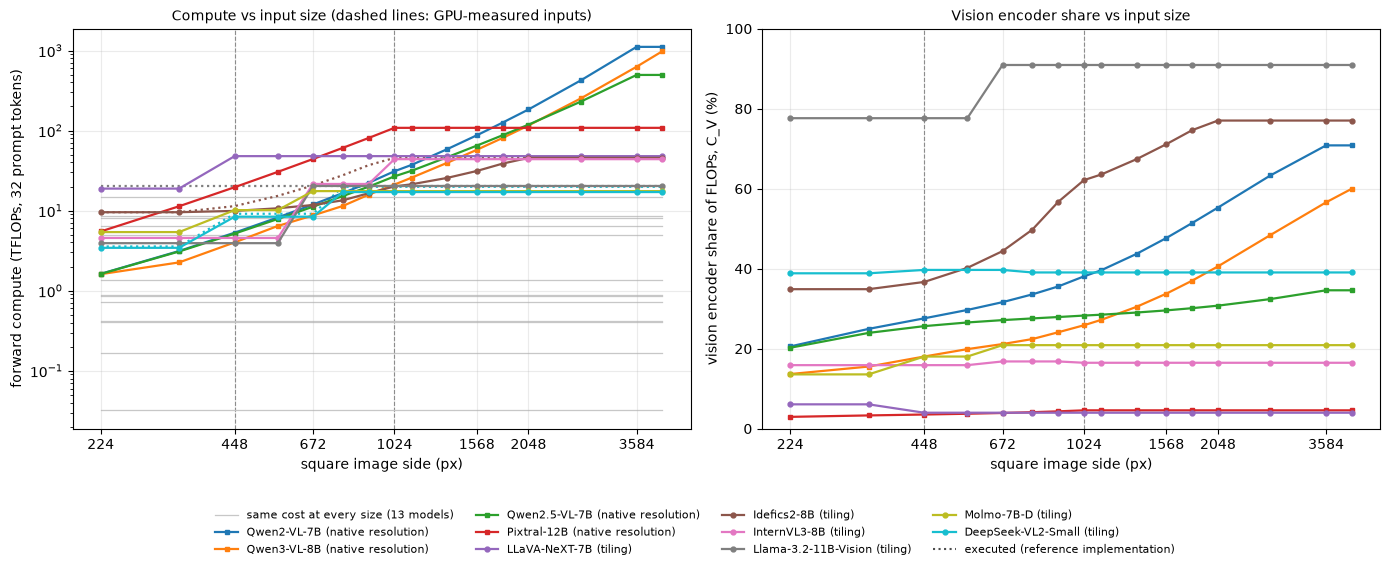

In [13]:
import matplotlib.pyplot as plt

totals = square.pivot(index='height', columns='model', values='total_g') / 1000
executed_totals = square.pivot(index='height', columns='model', values='executed_total_g') / 1000
share_curves = square.pivot(index='height', columns='model', values='vision_compute_share_pct')
varying = growth[growth['compute_levels'] > 1].sort_values('total_g_plateau', ascending=False)['model'].tolist()
constant = [name for name in totals.columns if name not in varying]
palette = plt.get_cmap('tab10')
colours = {name: palette(index % 10) for index, name in enumerate(varying)}
MARKERS = {'tiling': 'o', 'native resolution': 's'}

figure, (compute_axis, share_axis) = plt.subplots(1, 2, figsize=(14, 5.6))
for name in constant:
    compute_axis.plot(totals.index, totals[name], color='0.78', linewidth=0.9, zorder=1)
compute_axis.plot([], [], color='0.78', linewidth=0.9, label=f'same cost at every size ({len(constant)} models)')
for name in varying:
    marker = MARKERS.get(INPUT_HANDLING[name], 'o')
    compute_axis.plot(totals.index, totals[name], color=colours[name], marker=marker, markersize=3.5,
                      linewidth=1.6, label=f'{name} ({INPUT_HANDLING[name]})', zorder=3)
    if name in EXECUTION_DIFFERS:
        compute_axis.plot(executed_totals.index, executed_totals[name], color=colours[name], linestyle=':',
                          linewidth=1.6, zorder=2)
    share_axis.plot(share_curves.index, share_curves[name], color=colours[name], marker=marker, markersize=3.5,
                    linewidth=1.6)
compute_axis.plot([], [], color='0.3', linestyle=':', label='executed (reference implementation)')
for axis in (compute_axis, share_axis):
    for side in (SMALL_SIDE, REFERENCE_SIDE):
        axis.axvline(side, color='0.5', linestyle='--', linewidth=0.8, zorder=0)
    axis.set_xscale('log')
    ticks = [224, 448, 672, 1024, 1568, 2048, 3584]
    axis.set_xticks(ticks)
    axis.set_xticklabels([str(tick) for tick in ticks])
    axis.minorticks_off()
    axis.set_xlabel('square image side (px)')
    axis.grid(alpha=0.25)
compute_axis.set_yscale('log')
compute_axis.set_ylabel('forward compute (TFLOPs, 32 prompt tokens)')
compute_axis.set_title('Compute vs input size (dashed lines: GPU-measured inputs)', fontsize=10)
share_axis.set_ylabel('vision encoder share of FLOPs, C_V (%)')
share_axis.set_ylim(0, 100)
share_axis.set_title('Vision encoder share vs input size', fontsize=10)
handles, labels = compute_axis.get_legend_handles_labels()
figure.legend(handles, labels, fontsize=8, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
figure.tight_layout(rect=(0, 0.12, 1, 1))
for extension in ('png', 'pdf'):
    figure.savefig(FIGURE_DIR / f'nb32_compute_vs_input_size_draft.{extension}', dpi=300, bbox_inches='tight')
plt.show()

---
## 9. Summary of the numbers and closing the logs

In [14]:
summary_text = findings_markdown(growth, between, across, rank_agreement, share_ranges, executed_ratio,
                                 aspect_summary, agreement, model_count=len(TABLE_ORDER), budget_table=budget)
(MEASUREMENT_DIR / 'nb32_input_size_findings.md').write_text(summary_text, encoding='utf-8')
print(summary_text)
logger.close()
transcript.close()
transcript = None

# Notebook 32 - compute versus input size: findings

Intrinsic forward compute (revised Table 3 protocol, 32 prompt tokens) of 23 models on 16 square images (224-4096 px) and on 11 images of 1,048,576 pixels with different aspect ratios. CPU only; same cost model as Table 3 (validated within 0.008% of an op-level count at full depth, notebook 31).

## 1. How compute grows with the image

* 13 models cost the same at every square size (a fixed resize, or Gemma 4's fixed token budget): BLIP-2-OPT-2.7B, BLIP-large, CLIP-ViT-L/14, Chameleon-7B, Gemma-4-12B, Gemma-4-26B-A4B, IDEFICS-9B, InstructBLIP-Vicuna-7B, Janus-Pro-7B, LLaVA-1.5-7B, SigLIP2-So400m/14, ViLT-B/32, SigLIP-L/16.
* 10 models grow until a plateau. Plateau over the 448^2 cost:
  * Qwen3-VL-8B (native resolution): x244.3 (plateau 980,791 G from 4096 px; 16 distinct levels; 1024/448 = x5.27)
  * Qwen2-VL-7B (native resolution): x209.3 (plateau 1,110,274 G from 3584 px; 15 distinct levels; 1024/448 = x5.85)
  * Qwen2.5-VL-7B (na